# Индивидуальное задание: подбор одного гиперпараметра с помощью GridSearchCV

**Предмет:** Основы машинного обучения  
**Тема:** Подбор одного гиперпараметра с помощью `GridSearchCV`

**Цель:** подобрать оптимальную максимальную глубину дерева решений (`max_depth`) с помощью кросс-валидации, затем сравнить модель с подобранным параметром и модель с настройками по умолчанию на **отложенной тестовой выборке**.

План работы:
1. Загрузить датасет и разделить его на train/test.
2. Обучить дерево решений без подбора параметров.
3. Перебрать значения одного гиперпараметра `max_depth` от 1 до 15 с помощью `GridSearchCV`.
4. Построить график качества на обучении и кросс-валидации.
5. Оценить две модели на тестовых данных и сделать выводы.

> Датасет использован исключительно для учебной демонстрации методов машинного обучения. Модели не предназначены для медицинских решений.

## 1. Библиотеки и воспроизводимость

Используем `scikit-learn` для обучения и подбора параметров, `pandas` для таблиц и `matplotlib` для графиков. Значение `random_state=42` фиксирует случайные разбиения и поведение дерева решений.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
print(f"scikit-learn: {sklearn.__version__}")

scikit-learn: 1.8.0


## 2. Исходные данные

**Breast Cancer Wisconsin** — встроенный набор данных `scikit-learn`. В нём **569 объектов**, **30 числовых признаков** и два класса: `0` — злокачественная опухоль, `1` — доброкачественная. Для эксперимента важно лишь то, что это задача бинарной классификации. Данные загружаются локально и не требуют интернета.

In [2]:
dataset = load_breast_cancer()
X, y = dataset.data, dataset.target

print("Размер матрицы признаков:", X.shape)
print("Размер вектора ответов:", y.shape)
print("Классы:", dict(enumerate(dataset.target_names)))
print("Количество объектов каждого класса:")
print(pd.Series(y).map({0: "Злокачественная", 1: "Доброкачественная"}).value_counts().to_string())

assert X.shape == (569, 30)
assert len(np.unique(y)) == 2
pd.DataFrame(X, columns=dataset.feature_names).head()

Размер матрицы признаков: (569, 30)
Размер вектора ответов: (569,)
Классы: {0: np.str_('malignant'), 1: np.str_('benign')}
Количество объектов каждого класса:
Доброкачественная    357
Злокачественная      212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Разделение на обучающую и тестовую выборки

75% наблюдений выделим для обучения и кросс-валидации, 25% — для финального тестирования. `stratify=y` сохраняет примерно те же доли классов в обеих выборках.

**Важно:** `GridSearchCV` будет работать только с `X_train`, `y_train`. Тестовая выборка не участвует в выборе глубины — это защищает оценку качества от утечки информации.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE,
)
print("Обучающая выборка:", X_train.shape[0], "объектов")
print("Тестовая выборка:", X_test.shape[0], "объектов")

Обучающая выборка: 426 объектов
Тестовая выборка: 143 объектов


## 4. Модель без подбора гиперпараметра

Для сравнения обучим обычный `DecisionTreeClassifier`, не задавая `max_depth`. По умолчанию глубина дерева не ограничена. Это может давать слишком сложную модель.

In [4]:
baseline = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
print("Фактическая глубина дерева без настройки:", baseline.get_depth())

Фактическая глубина дерева без настройки: 7


## 5. GridSearchCV: подбор **только одного** гиперпараметра

Гиперпараметр **`max_depth`** задаёт максимальную глубину дерева решений:
- небольшая глубина → модель простая, может **недообучаться**;
- слишком большая глубина → модель подстраивается под обучающие примеры, может **переобучаться**.

`GridSearchCV` перебирает **15 значений** (`1, 2, ..., 15`) и для каждого использует **5-кратную стратифицированную кросс-валидацию**. На каждом разбиении модель обучается на 4/5 обучающей части и проверяется на оставшейся 1/5. Средняя **accuracy** определяет лучший вариант.

Итого выполняется **15 × 5 = 75** обучений для оценки кандидатов. После выбора лучшей глубины `GridSearchCV` автоматически переобучает лучший вариант на всей обучающей выборке (`refit=True`).

In [5]:
param_grid = {"max_depth": list(range(1, 16))}  # Настраиваем ровно ОДИН параметр

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    refit=True,
)
search.fit(X_train, y_train)

assert list(param_grid) == ["max_depth"]
print("Лучшее значение max_depth:", search.best_params_["max_depth"])
print(f"Средняя accuracy по 5 фолдам: {search.best_score_:.4f}")
print("Фактическая глубина лучшего дерева:", search.best_estimator_.get_depth())

Лучшее значение max_depth: 3
Средняя accuracy по 5 фолдам: 0.9390
Фактическая глубина лучшего дерева: 3


## 6. Таблица результатов поиска

Сравним среднюю точность на обучающих фолдах (`mean_train_score`) и проверочных фолдах (`mean_test_score`). При большой глубине точность на обучении может достигнуть 100%, но это **не означает**, что модель так же хорошо справляется с новыми данными.

In [6]:
results = pd.DataFrame({
    "max_depth": search.cv_results_["param_max_depth"].astype(int),
    "train_accuracy": search.cv_results_["mean_train_score"],
    "cv_accuracy": search.cv_results_["mean_test_score"],
    "cv_std": search.cv_results_["std_test_score"],
    "rank": search.cv_results_["rank_test_score"],
})
print(results.round(4).to_string(index=False))

 max_depth  train_accuracy  cv_accuracy  cv_std  rank
         1          0.9266       0.8920  0.0190    15
         2          0.9595       0.9249  0.0354     4
         3          0.9783       0.9390  0.0216     1
         4          0.9888       0.9272  0.0189     3
         5          0.9947       0.9272  0.0216     2
         6          0.9977       0.9225  0.0176    14
         7          0.9988       0.9248  0.0161     5
         8          1.0000       0.9248  0.0161     5
         9          1.0000       0.9248  0.0161     5
        10          1.0000       0.9248  0.0161     5
        11          1.0000       0.9248  0.0161     5
        12          1.0000       0.9248  0.0161     5
        13          1.0000       0.9248  0.0161     5
        14          1.0000       0.9248  0.0161     5
        15          1.0000       0.9248  0.0161     5


## 7. График: влияние глубины на качество

**Синяя линия** — средняя точность на обучающих фолдах.  
**Оранжевая линия** — средняя точность на валидационных фолдах.  
**Вертикальная пунктирная линия** — глубина, которую выбрал `GridSearchCV`.

На большой глубине обучение почти идеально, но валидационное качество хуже: это признак переобучения.

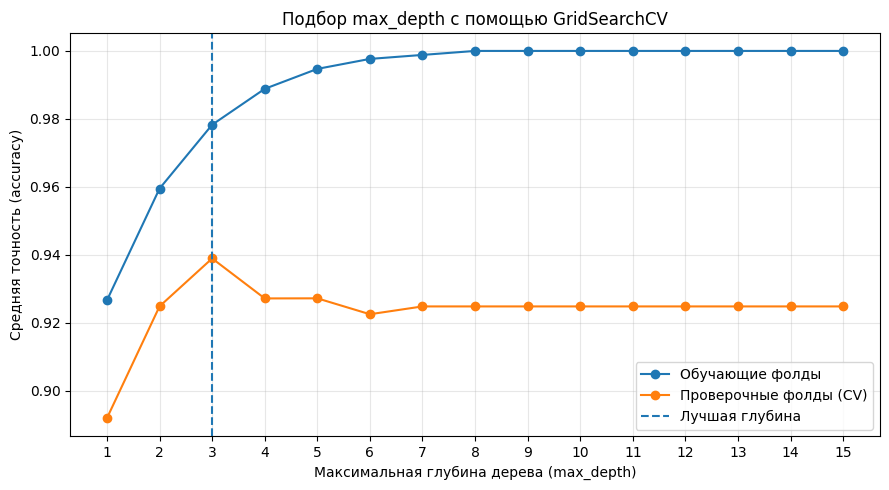

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(results["max_depth"], results["train_accuracy"], marker="o", label="Обучающие фолды")
ax.plot(results["max_depth"], results["cv_accuracy"], marker="o", label="Проверочные фолды (CV)")
ax.axvline(search.best_params_["max_depth"], linestyle="--", label="Лучшая глубина")
ax.set_xlabel("Максимальная глубина дерева (max_depth)")
ax.set_ylabel("Средняя точность (accuracy)")
ax.set_title("Подбор max_depth с помощью GridSearchCV")
ax.set_xticks(results["max_depth"])
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Независимое тестирование

Только **после** выбора глубины посмотрим на отложенную тестовую выборку. Сравним обычное дерево и лучшую модель по accuracy, precision, recall и F1.

Для `precision`, `recall`, `F1` рассматриваем **класс 0 (злокачественная опухоль)** как положительный, чтобы отдельно видеть, сколько объектов этого класса модель обнаруживает. Accuracy была критерием подбора, поэтому другие метрики **не обязаны улучшаться**.

In [8]:
def evaluate(model, name):
    pred = model.predict(X_test)
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (класс 0)": precision_score(y_test, pred, pos_label=0),
        "Recall (класс 0)": recall_score(y_test, pred, pos_label=0),
        "F1 (класс 0)": f1_score(y_test, pred, pos_label=0),
    }

best_model = search.best_estimator_
comparison = pd.DataFrame([
    evaluate(baseline, "Без подбора"),
    evaluate(best_model, "GridSearchCV"),
]).set_index("Модель")

print(comparison.round(4).to_string())
print(f"\nИзменение accuracy на тесте: {(comparison.loc['GridSearchCV', 'Accuracy'] - comparison.loc['Без подбора', 'Accuracy'])*100:+.2f} процентных пункта")

              Accuracy  Precision (класс 0)  Recall (класс 0)  F1 (класс 0)
Модель                                                                     
Без подбора     0.9231               0.8750            0.9245        0.8991
GridSearchCV    0.9441               0.9412            0.9057        0.9231

Изменение accuracy на тесте: +2.10 процентных пункта


## 9. Матрицы ошибок

В матрице ошибок **строки** соответствуют настоящему классу, а **столбцы** — предсказанному. Диагональные элементы — правильные ответы. Клетка «злокачественная → доброкачественная» показывает ошибку пропуска класса 0.

По матрицам можно проверить, чем отличается поведение моделей, даже когда итоговая accuracy похожа.

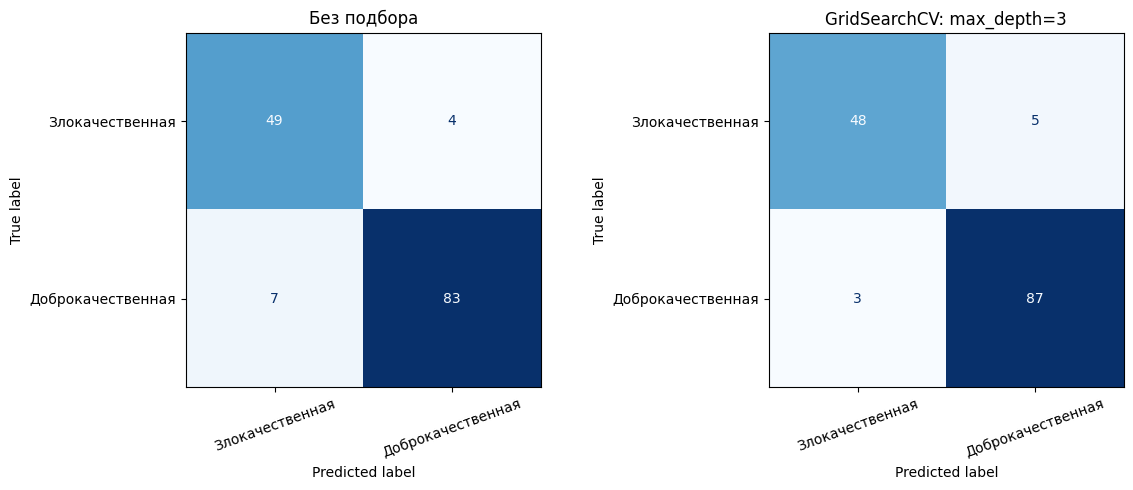

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ["Злокачественная", "Доброкачественная"]
for ax, model, title in zip(
    axes,
    [baseline, best_model],
    ["Без подбора", f"GridSearchCV: max_depth={search.best_params_['max_depth']}"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test),
        labels=[0, 1], display_labels=labels,
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=20)
plt.tight_layout()
plt.show()

## 10. Выводы

1. `GridSearchCV` автоматизирует перебор заданных значений **одного гиперпараметра**. В работе перебирается только `max_depth`.
2. Выбор проводится по **пяти фолдам обучающей выборки**; тестовые данные не используются для поиска.
3. На этой выборке при `random_state=42` оптимальная глубина — **3**, средняя accuracy на CV — примерно **0.939**.
4. На тесте accuracy модели без подбора — примерно **0.923**, после подбора — **0.944**; прирост составляет около **2.1 процентного пункта**.
5. **Важная оговорка:** recall для класса 0 после подбора слегка снизился (примерно с 0.925 до 0.906). То есть подбор по `accuracy` улучшил общий процент верных ответов, но не все метрики одновременно. Для прикладной задачи критерий подбора нужно выбирать с учётом стоимости ошибок.
6. Большая глубина дерева почти гарантирует высокую точность **на обучении**, но не обязательно на кросс-валидации и тесте.

**Итог:** даже настройка всего одного гиперпараметра может повысить качество модели, если выбирать его через кросс-валидацию и отдельно проверять полученный результат на тестовой выборке.